# Transience: the dip below dMMSE, and the rise that follows

**The claim.** A fixed-feature model trained by one-pass SGD first learns the **generalizing**
channel (degree 3: $Xyq$, optimally scaled one-step GD) and dips well below dMMSE out of
distribution. Train it longer and it learns the **memorizing** channel (degree 5: $\kappa_3$, the
pool's skewness) and OOD error climbs back toward dMMSE while ID error keeps falling. Nothing about
the model changes in between: no feature learning, one fixed random feature map, one learning rate.

**Why this setup makes the U visible.** Three changes from the earlier attempt, which measured a
+0.04 rise where theory said +0.15:

1. **The kernel is the structured one** -- $k_{\mathrm{even}}(c,c')\,(x_q\cdot x_q')$, features
   $\cos(\omega_j\cdot c)\,x_q$. It spends no capacity on modes that cannot carry the target, so
   $\kappa_3$ needs ~16k context features instead of ~150k, and it is reachable at a **wide** kernel.
2. **The width is 1.1x median, not 0.5x.** That is what went wrong before: at 0.5x the model does not
   extrapolate like its own polynomial, and the rise (an OOD effect, measured off the pool's
   contexts) was cancelled -- +0.04 measured against +0.15 predicted. Wide enough and it does; the
   check is that the dip lands on the degree-3 floor with ID and OOD together. With the generic
   kernel a width like this would have cost ~1e9 steps; here it is ~1e8.
3. **The pool is whitened with its mean kept** (`whiten_keepmean`: $\hat\Sigma=I$, $\hat\mu$ as
   drawn), the same pool as the earlier transience notebooks, so the degree-1 stage is visible before
   the dip. Centring it (`whiten`) or additionally zeroing $\mathrm{Tr}_1[\hat\kappa_3]$
   (`whiten_zeromean_tr1`) removes that stage and changes the dip and rise by <0.02.

**What the numbers should be** (d=4, 5 pairs, T=8, `whiten_keepmean`): OOD starts at 1.0, rises to
~1.15 as the degree-1 channel learns the pool mean $\hat\mu$ (a pool artifact, wrong off the pool),
dips to the degree-3 floor **0.604** -- 0.293 below dMMSE at 0.897 -- then rises toward **0.834** as
$\kappa_3$ is learned, ending 0.063 under dMMSE, with Ridge far below at 0.188. ID meanwhile falls
monotonically, 1.000 -> 0.529 -> 0.456: the same channels that cost OOD error pay on the pool. That
split is the memorization signature. The rise realized at learnability $L$ is $L^2$ of the full one,
so `TARGET_L` matters: 0.9 gives 81% of it, 0.7 gives 49%.

**Pairs > d on purpose.** At L = d the in-context regression is exactly determined, which reads
oddly. 5 pairs in 4 dimensions ends 0.063 under dMMSE; 6 pairs ends nearer still, for about twice
the compute. The sizing cell below measures the step rate and prints the cost before the loop runs.

## Colab setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os

GIT_USER = "JoeyTurn"
GIT_REPO = "kernels_can_icl"

!git clone https://github.com/{GIT_USER}/{GIT_REPO}.git

sys.path.insert(0, "/content/kernels_can_icl")
sys.path.insert(0, "/content/kernels_can_icl/expts/rf_scaling")

RESULTPATH = "/content/drive/MyDrive/results"
os.environ["RESULTPATH"] = RESULTPATH
os.makedirs(RESULTPATH, exist_ok=True)

Mounted at /content/drive
GitHub PAT: ··········
Cloning into 'kernel_ICL'...
remote: Enumerating objects: 955, done.
remote: Counting objects: 100% (490/490), done.
remote: Compressing objects: 100% (330/330), done.
remote: Total 955 (delta 307), reused 338 (delta 155), pack-reused 465 (from 1)
Receiving objects: 100% (955/955), 56.06 MiB | 25.33 MiB/s, done.
Resolving deltas: 100% (501/501), done.


In [ ]:
import os, sys, math, time, pickle, dataclasses
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

if not os.path.exists("/content/kernels_can_icl"):
    ROOT = Path.cwd()
    while ROOT != ROOT.parent and not (ROOT / "kernels_can_icl" / "__init__.py").exists():
        ROOT = ROOT.parent
    sys.path.insert(0, str(ROOT))
    sys.path.insert(0, str(ROOT / "expts" / "rf_scaling"))
    RESULTPATH = str(ROOT / "expts" / "rf_scaling" / "results")
    os.makedirs(RESULTPATH, exist_ok=True)

import kicl_floor as KF
import transience_utils as TU
import structured_rf as SR

_missing = [n for n in ("StructuredRF", "StructuredSpectrum", "context_of") if not hasattr(SR, n)]
_missing += [f"TU.{n}" for n in ("ChannelProbe", "implemented", "K3_KINDS") if not hasattr(TU, n)]
if "whiten_zeromean_tr1" not in open(KF.__file__, encoding="utf-8").read():
    _missing.append("kicl_floor pool kind whiten_zeromean_tr1")
if _missing:
    raise RuntimeError(f"stale clone (missing {_missing}). Run `!git -C /content/kernels_can_icl pull`, "
                       "then Runtime > Restart.")

torch.backends.cuda.matmul.allow_tf32 = False     # kappa_3 is ~1e-7 of the top mode
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if DEVICE.type == "cuda" else 0.0
print("device:", DEVICE, f"({torch.cuda.get_device_name(0)}, {GPU_GB:.1f} GB)" if GPU_GB
      else "(CPU -- runs the RU_SMOKE version)")

device: cuda (NVIDIA A100-SXM4-40GB, 42.4 GB)


## Configuration

T=8 is the window: at T=4 the rise overshoots dMMSE, at T=16 both the dip and the rise halve.
Predicted at d=4, 5 pairs with `whiten_keepmean`: dip +0.293 below dMMSE, full rise +0.229, ending
0.063 under dMMSE. 6 pairs ends nearer dMMSE for about twice the compute.

The step budget is set by $\kappa_3$, whose eigenvalue is ~1e-7 of the top mode, so runs are tens of
millions of steps on a model with only ~65k parameters. Data is generated in shards and sliced into
batches, because at this size the per-step cost is dominated by making the data, not by the model.

In [ ]:
SMOKE = bool(int(os.environ.get("RU_SMOKE", "0"))) or DEVICE.type != "cuda"

DIM, PAIRS, EPS = 4, 5, 0.05           # pairs > d; 6 pairs ends nearer dMMSE at ~2x the cost
CFG = KF.make_config(DIM, PAIRS, EPS)
assert (CFG.dim, CFG.L, CFG.e) == (DIM, PAIRS, EPS), "stale kicl_floor.py -- git pull and restart"

# Whitened covariance with the sample mean kept: Sigma_hat = I, mu_hat as drawn (||mu_hat||^2 ~ d/T),
# higher cumulants as drawn. Measured ladder at d=4, 5 pairs, T=8 (OOD): q 1.119, +y2q 1.150,
# deg<=3 0.604, +y3Xq 0.639, +kappa_3 0.834, deg<=5 0.781, against dMMSE 0.897 and Ridge 0.188 --
# so the curve rises ABOVE the null first (the degree-1 channel learns mu_hat, a pool artifact that
# is wrong off the pool), then dips 0.293 below dMMSE, then rises 0.229 to end 0.063 under it.
# Alternatives change the dip and rise by <0.02: "whiten" centres the pool (no degree-1 stage, q
# 1.000, deg<=3 0.544) and "whiten_zeromean_tr1" also zeroes Tr_1[kappa_3] (deg<=3 0.533, no y2q bump).
POOL_KIND    = "whiten_keepmean"
# The model must extrapolate like its polynomial or the rise (an OOD effect) cancels. 0.5x is far too
# local; at this context length (D_ctx = 25) 1.1x already suffices -- the dip lands on the degree-3
# floor with ID and OOD together. The long-context runs in rf_ridge_reach needed 1.5x.
WIDTH_FACTOR = 1.1
SEED         = 0
LR_FRAC      = 0.75
TARGET_FAMILY = "y2XX"                 # the kappa_3 channel: train until it is learned
TARGET_L     = 0.6
CKPT_SECONDS = 600

if SMOKE:
    DIM, PAIRS = 3, 4
    CFG = KF.make_config(DIM, PAIRS, EPS)
    T_LIST, TRIALS = [8], 1
    M_FEATURES, BATCH, TEST_SZ, N_PROBE = 1_024, 64, 2_048, 4_000
    SMOKE_STEPS, GEN_SHARD = 4_000, 4_096
else:
    T_LIST   = [8]#[8, 4, 16, 32, 64]#, 2, 1, 128]                     # add 4 and 16 for the T sweep; finished runs are skipped
    TRIALS   = 3                       # 3 once the shape is confirmed
    M_FEATURES = "auto"                # context features for kappa_3 at TARGET_L (~2^14 here)
    BATCH, TEST_SZ, N_PROBE = 1024, 65_536, 200_000
    SMOKE_STEPS, GEN_SHARD = None, 65_536
CURVE_TS = T_LIST
N_EVAL, EVAL_CHUNK = 48, 256

print(CFG.describe())
print(f"SMOKE={SMOKE}  M={M_FEATURES}  batch={BATCH}  T={T_LIST}  trials={TRIALS}")

d4 5pairs eps0.05: d=4 L_cfg=6 (L=5 pairs) e=0.05 v=0.25000 sigma_beta2=1.0 D=29 norm2=1.05000
SMOKE=False  M=auto  batch=1024  T=[8]  trials=3


## Width, sizing and the ladder

Every rung is printed with the features it needs and the steps it takes, so the two-stage structure
is visible before anything runs: `Xy` is the dip, `y2XX`/`yX_yX` are the rise, and the rungs between
them (`y4`, `y3X`) move the curve much less.

In [ ]:
_td, _ = TU.make_pool_distr(CFG, 8, SEED, POOL_KIND, DEVICE)
_, _, _Xc, _yc, _Xq = TU.gen_raw(_td, CFG, 3000, "pretrain")
_C = SR.context_of(_Xc, _yc)
MEDIAN_CTX = float(torch.cdist(_C[:1500].double(), _C[1500:].double()).flatten().median())
WIDTH = WIDTH_FACTOR * MEDIAN_CTX
D_CTX = _C.shape[1]
SPEC = SR.StructuredSpectrum(CFG, WIDTH)
_env = float(((_C.double() ** 2).sum(1)).std()) / (2 * WIDTH ** 2)
print(f"D_ctx = {D_CTX}   median = {MEDIAN_CTX:.3f}   width = {WIDTH:.3f} ({WIDTH_FACTOR}x)   "
      f"envelope spread {_env:.3f}")

_per_feature = 4 * (D_CTX + BATCH + EVAL_CHUNK) + 8 * DIM
if M_FEATURES == "auto":
    M_FEATURES = 2 ** math.ceil(math.log2(SPEC.M_for(TARGET_FAMILY, TARGET_L)))
    if GPU_GB and M_FEATURES * _per_feature > 0.4 * GPU_GB * 1e9:
        M_FEATURES = 2 ** int(math.log2(0.4 * GPU_GB * 1e9 / _per_feature))
        print(f"capped by memory: M = {M_FEATURES:,}")
L_CEIL = SPEC.L_ceiling(TARGET_FAMILY, M_FEATURES)

_m = SR.StructuredRF(M_FEATURES, D_CTX, DIM, WIDTH, SEED, DEVICE)
LAM1 = _m.top_eigenvalue(_C[:512].to(DEVICE), _Xq[:512].squeeze(1).to(DEVICE))
ETA = LR_FRAC * 2.0 / LAM1
MAX_STEPS = int(math.ceil(SPEC.steps_for(TARGET_FAMILY, ETA, LAM1, min(TARGET_L, 0.999 * L_CEIL))))
EVAL_STEPS = sorted({max(1, int(round(s))) for s in np.geomspace(1, MAX_STEPS, N_EVAL)})
del _m

print(f"M = {M_FEATURES:,} context features ({M_FEATURES * DIM:,} parameters, "
      f"{M_FEATURES * _per_feature / 1e9:.2f} GB)")
print(f"lambda_1 {LAM1:.4f} -> eta {ETA:.2f};  {TARGET_FAMILY} ceiling {L_CEIL:.3f};  "
      f"MAX_STEPS {MAX_STEPS:,} (n_seen {MAX_STEPS * BATCH:,})")
print(f"\n{'rung':>8} {'lambda/lam1':>12} {'M for L=.9':>12} {'ceiling':>9} {'steps to .9':>13}")
for row in SPEC.describe(M_FEATURES, ETA, LAM1, kinds=("q", "y2", "Xy", "XX", "y4", "y3X", "y2XX")):
    print(f"{row[0]:>8} {row[1]:>12} {row[2]:>12} {row[3]:>9} {row[4] if len(row) > 4 else '':>13}")

D_ctx = 25   median = 4.409   width = 4.850 (1.1x)   envelope spread 0.105
M = 8,192 context features (32,768 parameters, 0.04 GB)
lambda_1 0.1824 -> eta 8.22;  y2XX ceiling 0.738;  MAX_STEPS 3,347,626 (n_seen 3,427,969,024)

    rung  lambda/lam1   M for L=.9   ceiling   steps to .9
       q    1.000e+00            2     1.000             2
      y2    1.685e-03          170     1.000           911
      Xy    4.272e-04          288     1.000         3,594
      XX    1.083e-04          442     0.999        14,173
      y4    2.838e-06        3,385     0.978       540,823
     y3X    7.197e-07        7,378     0.918     2,132,982
    y2XX    1.825e-07       13,317     0.738     4,888,644


In [ ]:
# The ladder for these pools: where the curve should go, before running it.
LADDER_ENGINE = KF.build_ladder_engine(CFG)
SHOWN = ("q", "Xy", "XX", "y3X", "yX_yX", "yXdotX")
print(f"{'T':>4} | " + " ".join(f"{KF.LADDER_LABELS[k]:>16}" for k in SHOWN) +
      f" | {'dMMSE':>7} {'Ridge':>7} | {'dip':>6} {'rise':>6}")
for _T in T_LIST:
    _f, _o = [], []
    for _t in range(TRIALS):
        torch.manual_seed(SEED + 1009 * _t + 17 * _T)
        _b = KF.draw_betas(_T, CFG, POOL_KIND, torch.device("cpu"))
        _f.append(KF.ladder_floors(LADDER_ENGINE, _b, CFG.sigma_beta2))
        _o.append(KF.oracle_mse_one_betas(_b, DIM, CFG.L_cfg, CFG.v, CFG.e, 1.0, CFG.norm2, 4000,
                                          np.random.default_rng(_t)))
    _lad = {k: float(np.mean([f[k][1] for f in _f])) for k in KF.LADDER_LABELS}
    _dm = float(np.mean([o["dmmse_ood"] for o in _o])); _rg = float(np.mean([o["ridge_ood"] for o in _o]))
    print(f"{_T:>4} | " + " ".join(f"{_lad[k]:>16.3f}" for k in SHOWN) +
          f" | {_dm:>7.3f} {_rg:>7.3f} | {_dm - _lad['XX']:>+6.3f} {_lad['yX_yX'] - _lad['XX']:>+6.3f}")

   T |                q             +Xyq    +XXq (deg<=3)            +y3Xq           +yX_yX +yXdotX (deg<=5) |   dMMSE   Ridge |    dip   rise
   8 |            1.129            0.596            0.608            0.644            0.810            0.792 |   0.896   0.190 | +0.287 +0.202


In [ ]:
def estimate_runtime():
    m = SR.StructuredRF(M_FEATURES, D_CTX, DIM, WIDTH, 0, DEVICE)
    td, _ = TU.make_pool_distr(CFG, 8, SEED, POOL_KIND, DEVICE)
    Xf, yq, Xc, yc, Xq = TU.gen_raw(td, CFG, GEN_SHARD, "pretrain")
    C, xq = SR.context_of(Xc, yc), Xq.squeeze(1)
    sync = torch.cuda.synchronize if DEVICE.type == "cuda" else (lambda: None)
    n = min(200, GEN_SHARD // BATCH)
    for i in range(3):
        m.step(C[:BATCH], xq[:BATCH], yq[:BATCH], ETA)
    sync(); t0 = time.time()
    for i in range(n):
        s = slice(i * BATCH, (i + 1) * BATCH)
        m.step(C[s], xq[s], yq[s], ETA)
    sync()
    per = (time.time() - t0) / n
    del m
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    runs = len(T_LIST) * TRIALS
    print(f"{per * 1e6:.0f} us/step -> {MAX_STEPS * per / 3600:.1f} h per run x {runs} runs = "
          f"{runs * MAX_STEPS * per / 3600:.1f} h")
    print("(at this model size the step is launch-latency bound, so the shard stream matters more "
          "than the matmul)")

estimate_runtime()

377 us/step -> 0.4 h per run x 3 runs = 1.1 h
(at this model size the step is launch-latency bound, so the shard stream matters more than the matmul)


## The runs

Per (T, trial): fresh pool, fresh features, one-pass SGD on a stream that never repeats a sample.
Each evaluation also runs the **channel probe**: the model's own coordinates in the degree-<=5 ICL
basis, so the $\kappa_3$ fraction can be read directly, and a knock-out that removes $\kappa_3$ from
the model's predictions and re-scores them. If the rise is $\kappa_3$, the knocked-out curve should
not rise.

In [ ]:
TAG = f"d{DIM}p{PAIRS}e{EPS:g}_M{M_FEATURES}_b{BATCH}_w{WIDTH_FACTOR}{'_smoke' if SMOKE else ''}"
PRE3 = KF.build_floor_engine(CFG, (3,))[3]

def ckpt_path(T, trial):
    return os.path.join(RESULTPATH, f"rf_u_shape_{TAG}_T{T}_t{trial}.pt")

def _fingerprint(T, trial, seed):
    return dict(dim=DIM, pairs=PAIRS, M=M_FEATURES, batch=BATCH, width=round(WIDTH, 6), T=T,
                pool=POOL_KIND, eps=CFG.e, test_sz=TEST_SZ, seed=seed)

def _same(got, fp):
    return (isinstance(got, dict) and set(got) == set(fp)
            and all(math.isclose(got[k], fp[k], rel_tol=1e-3) if k == "width" else got[k] == fp[k] for k in fp))

def save_ckpt(path, obj, attempts=4):
    for i in range(attempts):
        try:
            torch.save(obj, path + ".tmp")
            os.replace(path + ".tmp", path)
            return True
        except Exception as err:
            print(f"   checkpoint write failed ({err}); retry {i + 1}")
            time.sleep(2 + 3 * i)
    return False

def train_run(T, trial):
    seed = SEED + 1009 * trial + 17 * T
    path, fp = ckpt_path(T, trial), _fingerprint(T, trial, seed)
    td, betas = TU.make_pool_distr(CFG, T, seed, POOL_KIND, DEVICE)
    tests = TU.make_tests(td, CFG, {"id": (TEST_SZ, "pretrain"), "ood": (TEST_SZ, "true")}, seed)
    ctx = {k: (SR.context_of(v["Xc"], v["yc"]), v["Xq"].squeeze(1)) for k, v in tests.items()}
    model = SR.StructuredRF(M_FEATURES, D_CTX, DIM, WIDTH, seed, DEVICE)

    # the probe needs the model's features as a flat (n, M*d) map of the notebook's flat inputs
    def feature_map(Xflat, chunk=None):
        c, xq = Xflat[:, :D_CTX], Xflat[:, D_CTX:]
        psi = model.features(c)
        return (psi[:, :, None] * xq[:, None, :].to(psi.dtype)).reshape(Xflat.shape[0], -1)

    st = torch.load(path, map_location="cpu", weights_only=False) if os.path.exists(path) else None
    if st is not None and not _same(st.get("fingerprint"), fp):
        print("   checkpoint is from a different configuration; starting over")
        st = None
    probe = TU.ChannelProbe(td, CFG, betas, N_PROBE, seed, feature_map, tests, chunk=EVAL_CHUNK) if N_PROBE else None
    if st is not None:
        model.load(st); start, curve, ref = int(st["step"]), list(st["curve"]), st["ref"]
        if start >= MAX_STEPS:
            print(f"T={T:>3} trial {trial}: complete ({start:,} steps)")
            return dict(T=T, trial=trial, seed=seed, curve=curve, **ref)
        print(f"T={T:>3} trial {trial}: resuming at step {start:,} of {MAX_STEPS:,}")
    else:
        lad = KF.ladder_floors(LADDER_ENGINE, betas, CFG.sigma_beta2)
        orc = {}
        for side in ("id", "ood"):
            pr, pd_ = TU.oracle_preds(tests[side]["Xc"], tests[side]["yc"], tests[side]["Xq"], betas, CFG)
            orc[f"ridge_{side}"] = TU.nmse(pr, tests[side]["y"], CFG)
            orc[f"dmmse_{side}"] = TU.nmse(pd_, tests[side]["y"], CFG)
        ref = dict(ladder={k: (float(v[0]), float(v[1])) for k, v in lad.items()}, oracles=orc, betas=betas)
        if probe is not None:
            ref["probe"] = probe.summary()
        start, curve = 0, []
        print(f"T={T:>3} trial {trial}: fresh. deg3 {lad['XX'][1]:.3f} -> kappa_3 {lad['yX_yX'][1]:.3f}"
              f" | dMMSE {orc['dmmse_ood']:.3f}  Ridge {orc['ridge_ood']:.3f}")

    def evaluate(step):
        row = dict(step=step, n=step * BATCH)
        preds = {}
        for side in ("id", "ood"):
            preds[side] = model.predict(*ctx[side], chunk=EVAL_CHUNK)
            row[side], row[f"{side}_se"] = TU.nmse_se(preds[side], tests[side]["y"], CFG)
        if probe is not None:
            row["probe"] = probe.measure(model.U.reshape(-1), preds)
        return row

    stop = MAX_STEPS if SMOKE_STEPS is None else min(MAX_STEPS, SMOKE_STEPS)
    t_ck, step = time.time(), start
    while step < stop:
        Xf, yq, Xc, yc, Xq = TU.gen_raw(td, CFG, GEN_SHARD, "pretrain")   # one shard, sliced into batches
        C, xq = SR.context_of(Xc, yc), Xq.squeeze(1)
        for i in range(0, GEN_SHARD - BATCH + 1, BATCH):
            step += 1
            s = slice(i, i + BATCH)
            model.step(C[s], xq[s], yq[s], ETA)
            if step in EVAL_STEPS or step == stop:
                row = evaluate(step)
                curve.append(row)
                k3 = (TU.implemented(ref["probe"], row["probe"]["coef"], TU.K3_KINDS)
                      if probe is not None else float("nan"))
                print(f"   step {step:>11,}  n_seen {step * BATCH:>13,}  ID {row['id']:.4f}  "
                      f"OOD {row['ood']:.4f}  kappa_3 {k3:>5.2f}")
            if step >= stop:
                break
        if time.time() - t_ck > CKPT_SECONDS or step >= stop:
            save_ckpt(path, dict(fingerprint=fp, step=step, curve=curve, ref=ref, **model.state()))
            t_ck = time.time()
    return dict(T=T, trial=trial, seed=seed, curve=curve, **ref)

records = []
t_all = time.time()
for trial in range(TRIALS):
    for T in T_LIST:
        records.append(train_run(T, trial))
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
SUMMARY = os.path.join(RESULTPATH, f"rf_u_shape_{TAG}_summary.pkl")
with open(SUMMARY, "wb") as f:
    pickle.dump(dict(records=records, config=dataclasses.asdict(CFG), dim=DIM, pairs=PAIRS,
                     M=M_FEATURES, batch=BATCH, width=WIDTH, eta=ETA, lam1=LAM1, max_steps=MAX_STEPS,
                     pool=POOL_KIND), f)
print(f"\ndone in {(time.time() - t_all) / 60:.1f} min -> {SUMMARY}")

T=  8 trial 0: fresh. deg3 0.568 -> kappa_3 0.795 | dMMSE 0.832  Ridge 0.189
   step           1  n_seen         1,024  ID 1.0184  OOD 1.0898  kappa_3 -0.00
   step           2  n_seen         2,048  ID 1.0310  OOD 1.0233  kappa_3 -0.00
   step           3  n_seen         3,072  ID 1.0285  OOD 1.0884  kappa_3 -0.00
   step           4  n_seen         4,096  ID 1.0096  OOD 1.0426  kappa_3 -0.00
   step           5  n_seen         5,120  ID 1.0183  OOD 1.1082  kappa_3 -0.00
   step           7  n_seen         7,168  ID 1.0204  OOD 1.1121  kappa_3 -0.00
   step           9  n_seen         9,216  ID 1.0229  OOD 1.0940  kappa_3 -0.00
   step          13  n_seen        13,312  ID 1.0110  OOD 1.0390  kappa_3  0.00
   step          18  n_seen        18,432  ID 1.0000  OOD 1.0516  kappa_3  0.00
   step          24  n_seen        24,576  ID 0.9867  OOD 1.0543  kappa_3  0.00
   step          34  n_seen        34,816  ID 0.9683  OOD 1.0337  kappa_3  0.00
   step          46  n_seen        47,104  

## The U

Linear axis. The dotted lines are the ladder rungs: the curve should fall to `+XXq` (degree 3) and
then climb toward `+yX_yX` ($\kappa_3$). ID keeps falling while OOD climbs -- the same channel that
helps on the pool hurts off it.

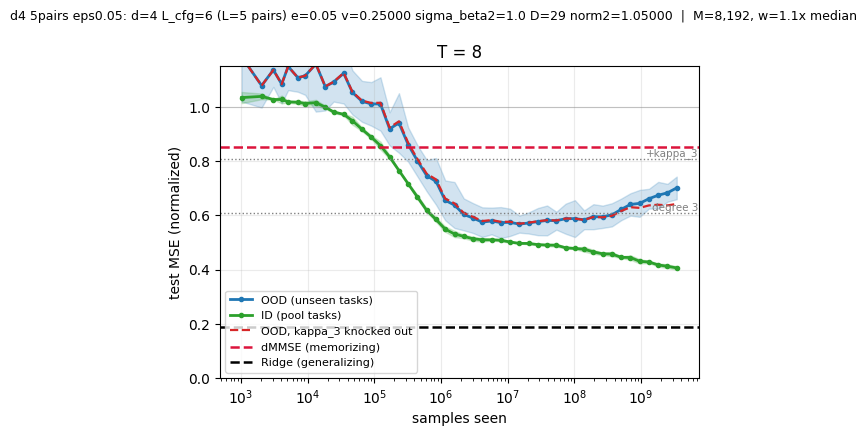

In [ ]:
def curves(T, side, key=None):
    rs = [r for r in records if r["T"] == T]
    ns = sorted({c["n"] for r in rs for c in r["curve"]})
    def val(c):
        return c[side] if key is None else c["probe"]["ko"][key][side]
    m = np.array([[np.mean([val(c) for c in r["curve"] if c["n"] == n] or [np.nan]) for n in ns] for r in rs])
    return np.array(ns, float), np.nanmean(m, 0), (np.nanstd(m, 0) if len(rs) > 1 else np.zeros(len(ns)))

def ref_of(T, key, side="ood"):
    rs = [r for r in records if r["T"] == T]
    i = 0 if side == "id" else 1
    return float(np.mean([(r["ladder"][key][i] if key in r["ladder"] else r["oracles"][f"{key}_{side}"])
                          for r in rs]))

fig, axs = plt.subplots(1, len(CURVE_TS), figsize=(5.6 * len(CURVE_TS), 4.4), squeeze=False)
for ax, T in zip(axs[0], CURVE_TS):
    for side, col, lab in (("ood", "C0", "OOD (unseen tasks)"), ("id", "C2", "ID (pool tasks)")):
        n, m, s = curves(T, side)
        ax.plot(n, m, "-o", ms=3, lw=2, color=col, label=lab)
        if np.any(s > 0):
            ax.fill_between(n, m - s, m + s, color=col, alpha=0.2)
    if any("probe" in c for r in records if r["T"] == T for c in r["curve"]):
        n, m, _ = curves(T, "ood", key="k3")
        ax.plot(n, m, "--", lw=1.6, color="C3", label="OOD, kappa_3 knocked out")
    ax.axhline(ref_of(T, "dmmse"), color="crimson", lw=1.8, ls="--", label="dMMSE (memorizing)")
    ax.axhline(ref_of(T, "ridge"), color="black", lw=1.8, ls="--", label="Ridge (generalizing)")
    for k, lab in (("XX", "degree 3"), ("yX_yX", "+kappa_3")):
        y = ref_of(T, k)
        ax.axhline(y, color="gray", lw=1.0, ls=":")
        ax.annotate(lab, (1.0, y), xycoords=("axes fraction", "data"), fontsize=7.5, color="gray",
                    ha="right", va="bottom")
    ax.axhline(1.0, color="gray", lw=0.8, alpha=0.4)
    ax.set_xscale("log"); ax.set_ylim(0, 1.15)
    ax.set_xlabel("samples seen"); ax.set_title(f"T = {T}")
    if T == CURVE_TS[0]:
        ax.set_ylabel("test MSE (normalized)"); ax.legend(fontsize=8, loc="lower left")
    ax.grid(alpha=0.25)
fig.suptitle(f"{CFG.describe()}  |  M={M_FEATURES:,}, w={WIDTH_FACTOR}x median", fontsize=9)
fig.tight_layout()
FIGDIR = os.path.join(RESULTPATH, "figs"); os.makedirs(FIGDIR, exist_ok=True)
fig.savefig(os.path.join(FIGDIR, f"rf_u_shape_{TAG}.pdf"), dpi=130, bbox_inches="tight")
plt.show()

In [ ]:
# Dip and rise, measured, against what the ladder predicts.
print(f"{'T':>4} | {'min OOD':>8} {'at n':>12} {'end OOD':>8} | {'dip':>16} {'rise':>16} | "
      f"{'kappa_3 impl':>12} {'rise w/o k3':>12}")
for T in T_LIST:
    rs = [r for r in records if r["T"] == T]
    dips, rises, mins, ends, k3s, rko = [], [], [], [], [], []
    for r in rs:
        y = np.array([c["ood"] for c in r["curve"]])
        n = np.array([c["n"] for c in r["curve"]])
        i = int(np.argmin(y))
        dm = r["oracles"]["dmmse_ood"]
        dips.append(min(dm, 1.0) - y[i]); rises.append(y[-1] - y[i])
        mins.append(y[i]); ends.append(y[-1])
        if "probe" in r["curve"][-1]:
            k3s.append(TU.implemented(r["probe"], r["curve"][-1]["probe"]["coef"], TU.K3_KINDS))
            ko = np.array([c["probe"]["ko"]["k3"]["ood"] for c in r["curve"]])
            rko.append(ko[-1] - ko[i])
    lad_dip = ref_of(T, "dmmse") - ref_of(T, "XX")
    lad_rise = ref_of(T, "yX_yX") - ref_of(T, "XX")
    nmin = np.mean([c["n"] for r in rs for c in [r["curve"][int(np.argmin([x["ood"] for x in r["curve"]]))]]])
    print(f"{T:>4} | {np.mean(mins):>8.3f} {nmin:>12,.0f} {np.mean(ends):>8.3f} | "
          f"{np.mean(dips):>+7.3f} (lad {lad_dip:+.3f}) {np.mean(rises):>+7.3f} (lad {lad_rise:+.3f}) | "
          f"{np.mean(k3s) if k3s else float('nan'):>12.2f} {np.mean(rko) if rko else float('nan'):>+12.3f}")
print("\n'rise w/o k3' removes the model's kappa_3 coordinates and re-scores: if the rise is kappa_3, "
      "this is ~0.")

   T |  min OOD         at n  end OOD |              dip             rise | kappa_3 impl  rise w/o k3
   8 |    0.558   41,570,304    0.702 |  +0.297 (lad +0.246)  +0.144 (lad +0.202) |         0.80       +0.084

'rise w/o k3' removes the model's kappa_3 coordinates and re-scores: if the rise is kappa_3, this is ~0.


## What the model implements

The fraction of each channel the model carries, measured from its own weights: the mean and $y^2q$
channels stay empty (the pool has no content for them), the ICL channel saturates at the dip, and
$\kappa_3$ comes in exactly where OOD turns up.

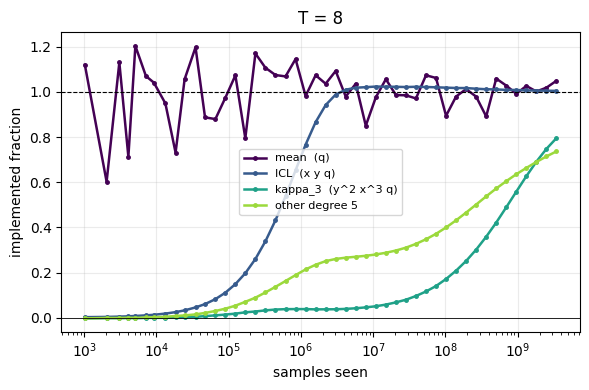

In [ ]:
if any("probe" in c for r in records for c in r["curve"]):
    fig, ax = plt.subplots(figsize=(6.0, 4.0))
    T = CURVE_TS[0]
    rs = [r for r in records if r["T"] == T]
    ns = sorted({c["n"] for r in rs for c in r["curve"] if "probe" in c})
    for (lab, kinds), col in zip(TU.PROBE_GROUPS, plt.cm.viridis(np.linspace(0, 0.85, len(TU.PROBE_GROUPS)))):
        m = [np.mean([TU.implemented(r["probe"], c["probe"]["coef"], kinds)
                      for r in rs for c in r["curve"] if c["n"] == n]) for n in ns]
        ax.plot(ns, m, "-o", ms=2.5, lw=1.8, color=col, label=lab)
    ax.axhline(1.0, color="black", lw=0.8, ls="--"); ax.axhline(0.0, color="black", lw=0.6)
    ax.set_xscale("log"); ax.set_xlabel("samples seen")
    ax.set_ylabel("implemented fraction"); ax.set_title(f"T = {T}")
    ax.legend(fontsize=8); ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, f"rf_u_shape_channels_{TAG}.pdf"), dpi=130, bbox_inches="tight")
    plt.show()
else:
    print("no probe in these runs (N_PROBE = 0)")